# EDA tổng quan — Music Genre Classification

Notebook này chỉ gọi vào `src/eda/eda.py`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Tự nạp lại code khi file trong src/ thay đổi
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
pd.set_option('display.max_columns', 100)
warnings.filterwarnings('ignore', category=FutureWarning)
print('Thư mục dự án:', ROOT)

Thư mục dự án: c:\Users\Hung\OneDrive\ドキュメント\May_hoc\PhanViec_Minh\Challege 2\MusicGenre


In [2]:
from src.utils.data_loader import load_config, load_raw, get_path
from src.eda.eda import EDA, GENRES

cfg = load_config()
train, test = load_raw(cfg)
eda = EDA(train, target='Class', fig_dir=get_path(cfg, 'figures'))
print('train:', train.shape, '| test:', test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


## 1. Tổng quan và dữ liệu thiếu

In [3]:
eda.overview()

,dtype,n_missing,pct_missing,n_unique
instrumentalness,float64,3541,24.60,3945
key,float64,1609,11.18,11
Popularity,float64,333,2.31,100
Id,int64,0,0.00,14396
acousticness,float64,0,0.00,3725
time_signature,int64,0,0.00,4
duration_in min/ms,float64,0,0.00,11805
tempo,float64,0,0.00,11392
valence,float64,0,0.00,1268
liveness,float64,0,0.00,1407


## 2. Phân bố lớp

Lệch lớp mạnh: lớp đông nhất gấp gần 13 lần lớp ít nhất, nên dùng StratifiedKFold.

,genre,count,pct
Class,,,
0,Acoustic/Folk,500,3.5
1,Alt Music,1098,7.6
2,Blues,1018,7.1
3,Bollywood,322,2.2
4,Country,310,2.2
5,HipHop,1157,8.0
6,Indie Alt,2069,14.4
7,Instrumental,461,3.2
8,Metal,1483,10.3


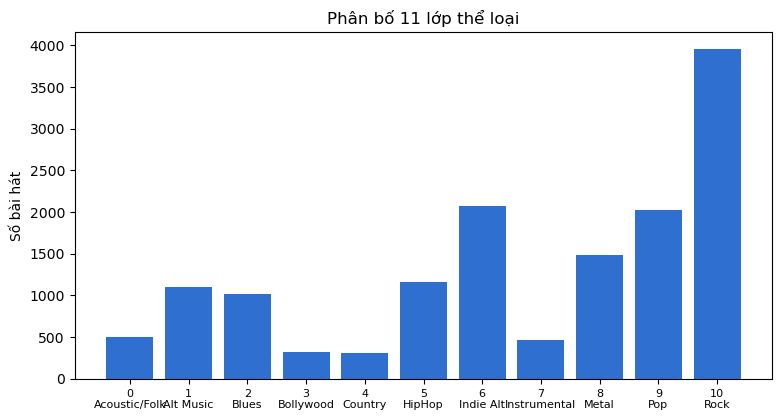

In [4]:
display(eda.class_distribution())
eda.plot_class_distribution()

## 3. Cột thời lượng trộn hai đơn vị

Giá trị dưới 30 là **phút**, còn lại là **mili-giây**. Không có giá trị nào nằm giữa.

In [5]:
print(eda.duration_units())
eda.duration_unit_by_class()

{'n_minutes': 2075, 'pct_minutes': 14.4, 'max_small': 29.886, 'min_large': 55775.0}


Class
0     1.000
1     0.000
2     0.000
3     1.000
4     1.000
5     0.000
6     0.000
7     1.000
8     0.000
9     0.168
10    0.036
Name: duration_in min/ms, dtype: float64

## 4. `key` thiếu nghĩa là cung Đô

Thang Spotify là 0..11 nhưng dữ liệu không có giá trị 0 nào.

In [6]:
eda.key_values()

key
1.0     1351
2.0     1582
3.0      411
4.0     1252
5.0     1115
6.0      963
7.0     1650
8.0      872
9.0     1590
10.0     825
11.0    1176
NaN     1609
Name: count, dtype: int64

## 5. `instrumentalness` thiếu có quy luật theo lớp

Không có giá trị 0 nào, và tỉ lệ thiếu khác hẳn nhau giữa các lớp: NA chính là 0.

In [7]:
print('Nhỏ nhất:', train['instrumentalness'].min())
eda.missing_by_class('instrumentalness')

Nhỏ nhất: 1e-06


Class
0     0.242
1     0.128
2     0.108
3     0.242
4     0.535
5     0.614
6     0.108
7     0.002
8     0.085
9     0.495
10    0.219
Name: instrumentalness, dtype: float64

## 6. Bài hát lặp lại với nhãn khác nhau

Đây là giới hạn trên của độ chính xác: cùng một bài được gán nhiều thể loại.

In [8]:
eda.duplicate_tracks()

{'pairs_repeated': 1103,
 'pairs_multi_label': 1043,
 'rows_in_repeated_pairs': 2323}

## 7. Thuộc tính âm thanh theo lớp

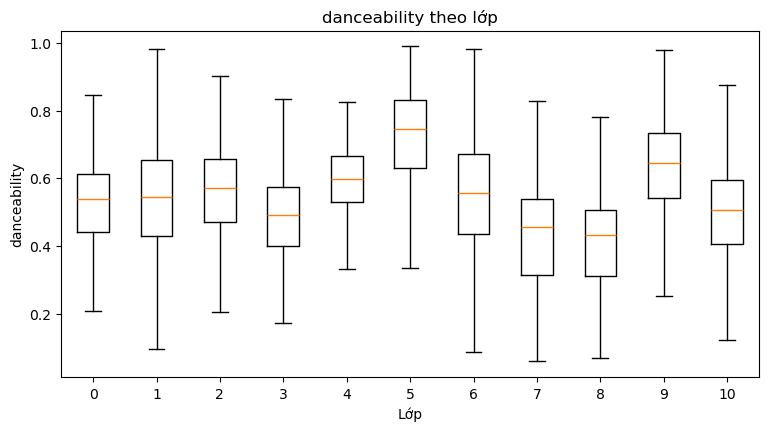

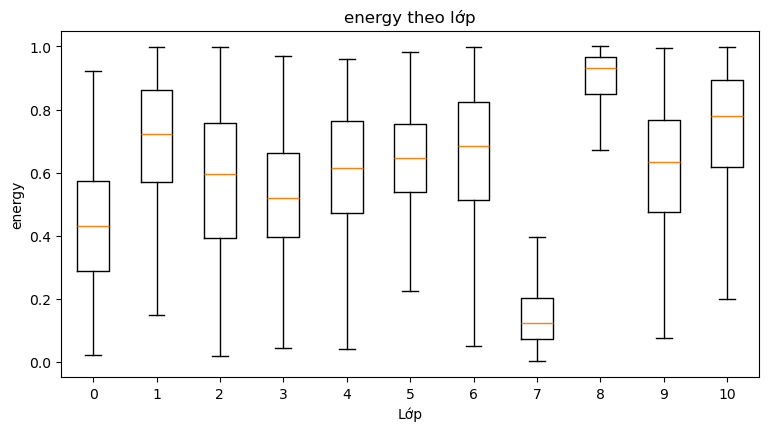

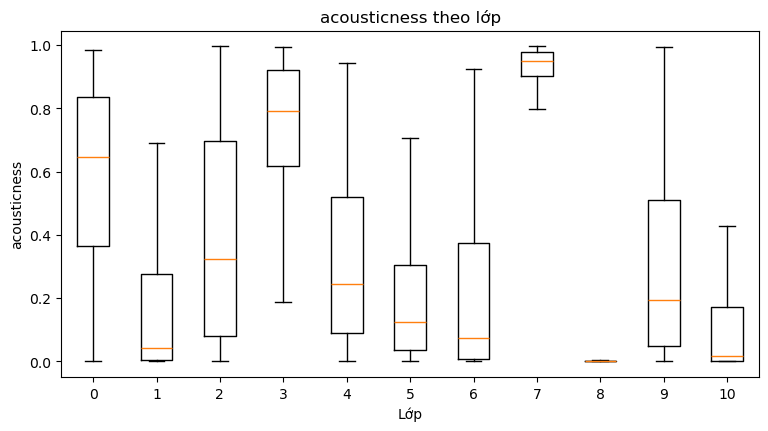

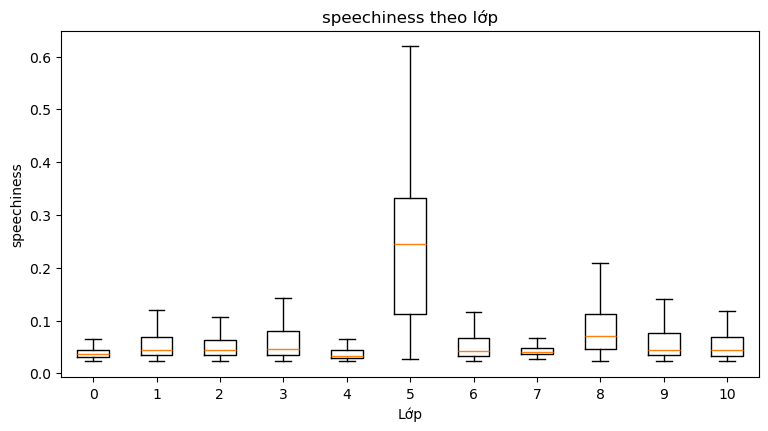

In [9]:
for col in ['danceability', 'energy', 'acousticness', 'speechiness']:
    eda.boxplot_by_class(col)

## 8. Kết quả làm sạch

In [10]:
from src.preprocess.Clean import Cleaner
cleaner = Cleaner(cfg)
tr, te = cleaner.run(train, test, 'Class')
print(cleaner.summary())
print('Còn thiếu:', tr.isna().sum().sum(), te.isna().sum().sum())

- Dòng train: 14396 (bỏ 0 dòng trùng hoàn toàn)
- Dòng test: 3600
- Dòng train ghi thời lượng bằng phút: 2075
- Giá trị thiếu trước khi xử lý: {'Popularity': 333, 'key': 1609, 'instrumentalness': 3541}

Còn thiếu: 0 0
